In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from sympy import *
import scipy.special as ssp
import scipy.optimize as so
from scipy.special import exp1 #gives access to special functions; i.e., the exponential integral function exp1(u)
from scipy.optimize import fsolve

# Part A

## Section 1

### Q1

For a confined aquifer with steady-state flow in one dimension, the mass flux entering the volume must equal the mass flux leaving it. We begin with the principle of mass conservation combined with Darcy's Law.

For one-dimensional flow in the x-direction only, this mass balance requires that the specific discharge, be constant along the flow path. Darcy's Law relates this specific discharge to the hydraulic gradient:

$$q = -K\frac{dh}{dx}$$

Since $q$ and $K$ are both constant under our assumptions of steady flow and a homogeneous aquifer, the hydraulic gradient must also be constant:

$$\frac{dh}{dx} = C_1$$

where $C_1$ is a constant. Integrating this expression with respect to $x$ gives:

$$h(x) = C_1x + C_2$$

where $C_2$ is a second integration constant. These constants are determined by applying the boundary conditions at the two rivers.

At the left river boundary, located at $x = 0$, the constant head is given as 5.8 m:

$$h(0) = C_2 = 5.8$$

At the right river boundary, located at $x = L = 1500$ m, the constant head is given as 5.4 m:

$$h(1500) = 5.4 =  C_1(1500) + 5.8 $$
$$C_1 = \frac{5.4 - 5.8}{1500} = \frac{-0.4}{1500} = -2.667 \times 10^{-4}$$

Substituting these constants back into our general solution gives the complete formula for hydraulic head as a function of distance:

$$h(x) = -2.667 \times 10^{-4}x + 5.8$$



The hydraulic head profile between the rivers is linear. This follows directly from the governing equation for one-dimensional, steady-state flow in a confined aquifer: 

$$\frac{d^2h}{dx^2} = 0$$

Functions with a zero second derivative have a constant slope, meaning they are linear. The general solution $h(x) = C_1x + C_2$ confirms this.

### Q2

From the mesh grid of our aquifer we can plot the changes in hydraulic head on different dimensions. For 3D we include all 3 dimensions, inversing the Z-axis for easier visual interpretation of depth. For 2D we take out a specific 'slice' of our mesh from the y-axis persepctive and plot the Z-array on the Y-axis and X-array on the X-axis. For both 3D adn 2D a color gradient have been used to show head level across the aquifer. Finally for the simplest depiction a 1D plot of our aquifer shows head level over distance (x).

In [3]:
# Aquifer dimensions 
L = 1500 # length in x (m) 
W = 1000 # width in y (m) – you can pick any number 
b =  8      # thickness in z (m) 
zb = 1 # base elevation (m) 
 
# Number of grid points in each direction, you can choose different numbers 
n_x = 20 
n_y = 20  
n_z = 9 
 
# Create 1D coordinate arrays 
x = np.linspace(0, L, n_x) 
y = np.linspace(0, W, n_y) 
z = np.linspace(zb, zb + b, n_z) 
 
# Generate 3D meshgrid 
# Using indexing='ij' gives arrays with shape (n_x, n_y, n_z) 
# This is convenient if you want to loop over x first, then y, then z. 
xi, yi, zi = np.meshgrid(x, y, z, indexing='ij') 


# Hydraulic head (linear in x)
h_L = 5.8
h_R = 5.4
h = h_L + (h_R - h_L) * (xi / L)

# Fix a y-slice - we take the middle
j = n_y // 2



#### 3D

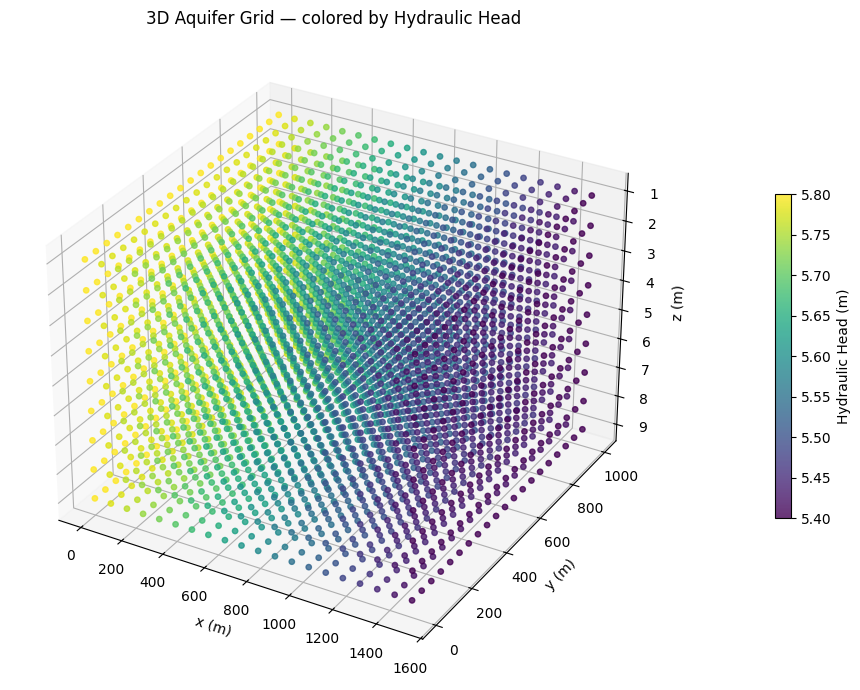

In [4]:
# --- 3D scatter plot colored by head ---
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(xi.ravel(),        # all x coords
                yi.ravel(),        # all y coords
                zi.ravel(),        # all z coords
                c=h.ravel(),       # color = head value
                cmap='viridis',
                s=15,
                alpha=0.8)

ax.invert_zaxis()

plt.colorbar(sc, ax=ax, label='Hydraulic Head (m)', shrink=0.5, pad=0.1)
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_zlabel('z (m)')
ax.set_title('3D Aquifer Grid — colored by Hydraulic Head')
plt.tight_layout()
plt.show()

#### 2D

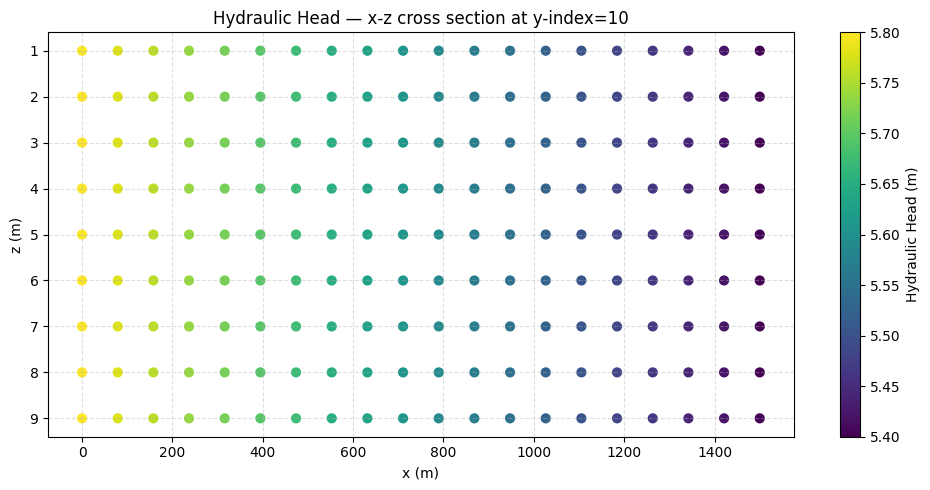

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.invert_yaxis()

sc = ax.scatter(xi[:, j, :].ravel(),   # x coords — shape (n_x, n_z) → 1D
                zi[:, j, :].ravel(),   # z coords — shape (n_x, n_z) → 1D
                c=h[:, j, :].ravel(),  # head values for color
                cmap='viridis',       # high head = red, low head = blue)
                s=40)

plt.colorbar(sc, label='Hydraulic Head (m)')
ax.set_xlabel('x (m)')
ax.set_ylabel('z (m)')
ax.set_title(f'Hydraulic Head — x-z cross section at y-index={j}')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

#### 1D

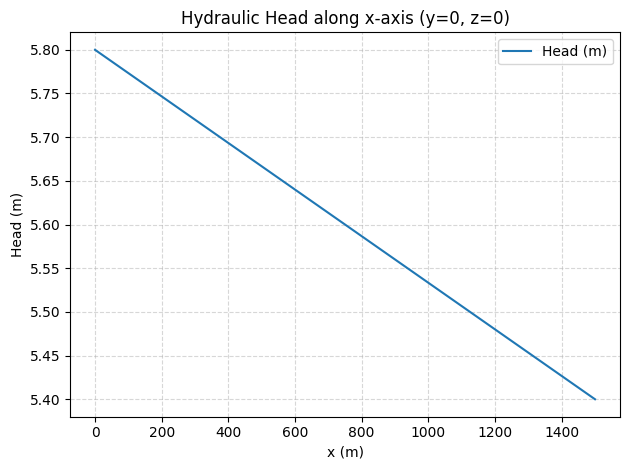

In [6]:
h = np.linspace(h_L, h_R, n_x)[:, np.newaxis, np.newaxis] * np.ones((1, n_y, n_z))

plt.plot(x, h[:, 0, 0], label='Head (m)')
plt.xlabel('x (m)')
plt.ylabel('Head (m)')
plt.title('Hydraulic Head along x-axis (y=0, z=0)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Q3

Assuming hydraulic cnoductivity $K = 5 \cdot 10^{-4}$ and porosity $n=0.33$ the following is computed:

$$ \text{Hydraulic Gradient}: \frac{dh}{dx} = \frac{h_R - h_L}{L} = -0.00027 $$
$$ \text{Specific Discharge}: q_x = -K\frac{dh}{dx} = 1.33 \cdot 10^{-7} \; [m/s] $$
$$ \text{Groundwater Velocity}: v_x = \frac{q_x}{n} = 4.04 \cdot 10^{-7} \; [m/s]$$

For this system with a costant uniform hydraulic gradient, the specific discharge and groundwater velocity remains constants across distance and depth.

In [7]:
K = 5e-4  # Hydraulic conductivity (m/s)
n = 0.33  # Porosity

# Hydraulic gradient (dh/dx)
dh_dx = (h_R - h_L) / L

q = -K * dh_dx # Darcy velocity (m/s)

v = q / n # Seepage velocity (m/s)

results = {
    'Hydraulic Gradient (dh/dx)': dh_dx,
    'Specific Discharge (q)': q,
    'Groundwater Velocity (v)': v
}

df_results = pd.DataFrame(results, index=[0])
display(df_results)

,Hydraulic Gradient (dh/dx),Specific Discharge (q),Groundwater Velocity (v)
0,-0.000267,1.333333e-07,4.040404e-07


## Section 2 - Steady-State Flow in a Two-Zone Confined Aquifer

### Q1


We move on to consider a Steady-State flow in a two-zone confined aquifer. 
- Each zone is homogeneous and isotopic, with constant but different hydraulic conductivities K1 and K2.
- The quifer is horizontal, 1-dimensional in the x-direction and has a constant thickness b.
- Both aquifer boundaries, $(x=0)$ and $(x=L=L1+L2)$ are in contact with rivers with consant heads, $h_0$ and $h_L$.

The Darcy veolocity $q_x$, must, due to conservation of mass, be the same in both zones, using Darcys law the following realation is obtained: 
$$q_x = -K_1\cdot \frac{h_{L1}-h_0}{L_1}=-K_2\cdot \frac{h_L-h_{L1}}{L_2}$$
$\Leftrightarrow$
$$K_1\cdot \frac{h_0 -h_{L1}}{L_1}=K_2\cdot \frac{h_{L1}-h_L}{L_2}$$

$h_{L_1}$ is the hydraulic head between the two zones, which is unkown. The above equation is solved (isolated) for $h_{L_1}$, using the provided information. 

 
The HL1 is the hydraulic head between the two zones. HL1 can be found via isolation, from the equation of the darcy velocity for the two zones. It can be done by manual isolation, or through python.

In [8]:
#Defining symbols from the equations in sympy:
K1, K2, hL, h0, hL1, L2, L1 = sp.symbols('K1, K2, hL, h0, hL1, L2, L1')

#Setting up the equation: 
hL1_equation = sp.Eq(K1*(h0-hL1)/L1, K2*(hL1-hL)/L2)

#Solving the equationfor hL1
hL1_equation  = sp.solve(hL1_equation, hL1)

#displaying the equation:
sol_hL1 = sp.Eq(hL1, hL1_equation [0])
print("The symbolic solution for h_L_1 is:")
display(sol_hL1)

The symbolic solution for h_L_1 is:


Eq(hL1, (K1*L2*h0 + K2*L1*hL)/(K1*L2 + K2*L1))

In [9]:
#define data:
h0 = 4 #m (head at left boundary)
hL = 2 #m (head at right boundary)
L1 = 500 #m (length of zone 1)
L2 = 500 #m (lenght of zone 2)
K1 = 10 #m/d (hydraulic conductivity og zone 1)
K2 = 200 #m/d (hydraulic conductivity of zone 2)
L = L1 + L2 
Zb = 0 #m (aquifer base elevation)
b = 2 #m (aquifer thickness)
n1 = 0.25 # (porosity of zone 1)
n2 = 0.35 # (porosity of zone 2)

In [10]:
#calculating hL1:
hL1 = ((K1*h0*L2)+(K2*hL*L1))/((K2*L1)+(K1*L2)) 

print(f"The interface head, hL1, is: {hL1:.2f} m") 

The interface head, hL1, is: 2.10 m


### Q2

A general linear equation $h(x)$ can be calculated, based on the initial head, the resulting head, and the length of which the hydraulic head drop has occured over using the general solution for steady 1-D flow *(which was dereived in section 1, Q1)*:

$$h(x)=c_1\cdot x+c_2$$

The boundary conditions are: 
- Zone 1 $(0 \leq x \leq L_1)$
- Zone 2 $(L_1 \leq x \leq L)$

In [11]:
x = sp.symbols('x')
zone1_c2 = h0 
zone1_c1 = (hL1 - h0) / L1
print(f"The expression h(x) for zone 1 is: h_zone1(x) = {zone1_c1:.2e}*x +{zone1_c2:.2f}")


zone2_c2 = hL1
zone2_c1 = (hL - hL1) / L2
print(f"The expression h(x) for zone 2 is: h_zone2(x) = {zone2_c1:.2e}*x +{zone2_c2:.2f}")

The expression h(x) for zone 1 is: h_zone1(x) = -3.81e-03*x +4.00
The expression h(x) for zone 2 is: h_zone2(x) = -1.90e-04*x +2.10


### Q3

The code from the previos excercise is modified to: 
- Compute $h_{L_1}$, this was already done i Q1. 
- Create an array of x values and compute the head along the entire aqufer.
- Plt $h(x)$ versus $x$

Visual representation of the head drop over the different zones of the system. 

In [12]:
"""
x values along the entire length
"""
x_vals = np.linspace(0, L1 + L2, 100)
print(f'Array of 100 x values along the aquifer length')
print(x_vals)

""" 
Calculation of head along the aqufier
"""
# piecewise function to calculate the head along the aquifer:
h_vals = np.piecewise(x_vals, [x_vals <= L1, x_vals > L1],
    [lambda x: zone1_c1 * x + zone1_c2, lambda x: zone2_c1 * (x -L1) + zone2_c2])

print(f'The head along the enitre aquifer')
print(h_vals)

Array of 100 x values along the aquifer length
[   0.           10.1010101    20.2020202    30.3030303    40.4040404
   50.50505051   60.60606061   70.70707071   80.80808081   90.90909091
  101.01010101  111.11111111  121.21212121  131.31313131  141.41414141
  151.51515152  161.61616162  171.71717172  181.81818182  191.91919192
  202.02020202  212.12121212  222.22222222  232.32323232  242.42424242
  252.52525253  262.62626263  272.72727273  282.82828283  292.92929293
  303.03030303  313.13131313  323.23232323  333.33333333  343.43434343
  353.53535354  363.63636364  373.73737374  383.83838384  393.93939394
  404.04040404  414.14141414  424.24242424  434.34343434  444.44444444
  454.54545455  464.64646465  474.74747475  484.84848485  494.94949495
  505.05050505  515.15151515  525.25252525  535.35353535  545.45454545
  555.55555556  565.65656566  575.75757576  585.85858586  595.95959596
  606.06060606  616.16161616  626.26262626  636.36363636  646.46464646
  656.56565657  666.66666667  6

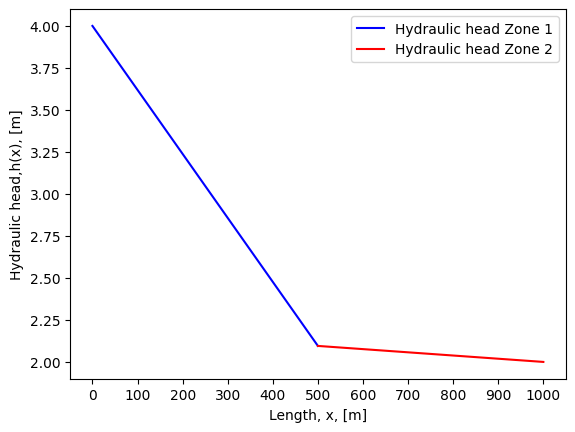

In [13]:
"""
Plot of h(x) vs. x

x_vals and h_vals have been defined and calculated in the code-box above, 
in order to color differentiat the two zones, the values are re-defined for each zone.
"""

# Define x values in each zone using linspace. 
x_zone1 = np.linspace(0, L1, 50)
x_zone2 = np.linspace(L1, L1 + L2, 50)

# Compute head in each zone using the constants derived in Q2. 
h_zone1 = zone1_c1 * x_zone1 + zone1_c2
h_zone2 = zone2_c1 * (x_zone2 - L1) + zone2_c2

# Plot figure
plt.figure()
plt.plot(x_zone1, h_zone1, color="blue", label="Hydraulic head Zone 1")
plt.plot(x_zone2, h_zone2, color="red", label="Hydraulic head Zone 2")
plt.xlabel("Length, x, [m]")
plt.ylabel("Hydraulic head,h(x), [m]")
plt.xticks(np.linspace(0, L, 11)) 
plt.legend()
plt.show()

### Q4: Conceptual questions

#### Q4.A 

The head profile is examined in two cases where different conductivity constants (K1 and K2) are assumed:
1) K1 >> K2 (eg. K1 = 1000 m/d, K2 = 10 m/d)
2) K1 and K2 are comparable

In each case, the head profile is plotted, and the shape is described.

In [14]:
def calculate_hL1(K1,K2,name):
    hL1 = ((K1*h0*L2)+(K2*hL*L1))/((K2*L1)+(K1*L2)) #m (interface head)

    print(f"The interface head, hL1: {hL1:.2f} m") 

    x = sp.symbols('x')
    zone1_c2 = h0 
    zone1_c1 = (hL1 - h0) / L1
    head_zone1 = zone1_c1*x+zone1_c2
    print(f"The expression h(x) for zone 1 is: h_zone1(x) = {zone1_c1:.2e}*x +{zone1_c2:.2f}")
    
    zone2_c2 = hL1
    zone2_c1 = (hL - hL1) / L2 
    head_zone2 = zone2_c1*x+zone2_c2
    print(f"The expression h(x) for zone 2 is: h_zone2(x) = {zone2_c1:.2e}*x +{zone2_c2:.2f}")
    
    x_zone1 = np.linspace(0, L1, 50)
    x_zone2 = np.linspace(L1, L1 + L2, 50)
    
    # Calculate head
    h_zone1 = zone1_c1 * x_zone1 + zone1_c2
    h_zone2 = zone2_c1 * (x_zone2 - L1) + zone2_c2
    
    # Plot figure
    plt.figure()
    plt.plot(x_zone1, h_zone1, color="blue", label="Hydraulic head Zone 1")
    plt.plot(x_zone2, h_zone2, color="red", label="Hydraulic head Zone 2")
    plt.xlabel("Length [m]")
    plt.ylabel("Hydraulic head [m]")
    plt.xticks(np.linspace(0, L, 11)) 
    plt.title(name)
    plt.legend()
    plt.show()

The interface head, hL1: 3.98 m
The expression h(x) for zone 1 is: h_zone1(x) = -3.96e-05*x +4.00
The expression h(x) for zone 2 is: h_zone2(x) = -3.96e-03*x +3.98


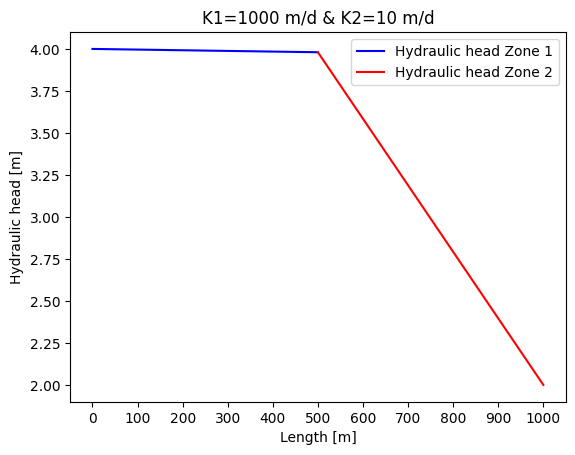

In [15]:
"""
Case 1, K1 >> K2


The first zone of the aquifer experiences almost no loss in head, due to the high conductivity constant K1.
The second zone of the aquifer experiences a great loss in head, due to the low conductivity constant K2.
There is a pronounced kink between the two zones.
"""
#define data:
new_K1 = 1000 #m/d (hydraulic conductivity of zone 1)
new_K2 = 10 #m/d (hydraulic conductivity of zone 2)

calculate_hL1(new_K1,new_K2,"K1=1000 m/d & K2=10 m/d")

The interface head, hL1: 3.10 m
The expression h(x) for zone 1 is: h_zone1(x) = -1.80e-03*x +4.00
The expression h(x) for zone 2 is: h_zone2(x) = -2.20e-03*x +3.10


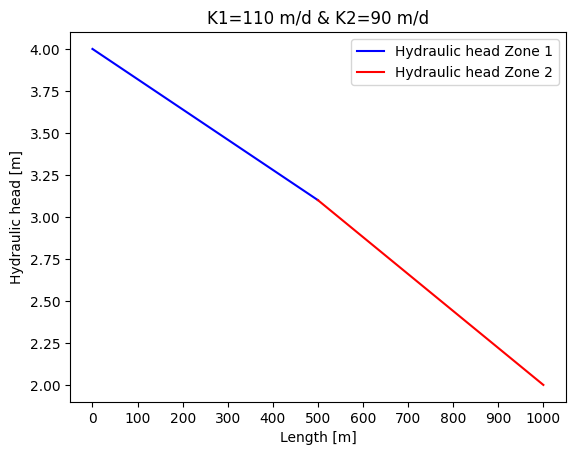

In [16]:
"""
Case 2, K1 and K2 are comparable. 

The head drops almost uniformly along the aquifer length. 
"""

#define data:
new_K1 = 110 #m/d (hydraulic conductivity of zone 1)
new_K2 = 90 #m/d (hydraulic conductivity of zone 2)

calculate_hL1(new_K1,new_K2,"K1=110 m/d & K2=90 m/d")

#### Q4.B 

Under steady-state conditions there is no source or sink, meaning the same volume of water that enters zone 1 must pass through and leave zone 2 (conservation of mass), thus the specific discharge must be same in both zones $q1 = q2$.

$-K_1 \frac{(h_{l1}-h_0)}{L_1} = -K_2 \frac{(h_{l}-h_{l1})}{L_2}$

Applying Darcys law in each zone, it becomes clear, that if K is high, a small hydraulic gradient is needed to convey the required flow, yielding a flat head profile as seen in zone 1 of the plot where K1 >> K2. Vice versa, if K is low, a steeper hydraulic gradient is required to push the same flow thorugh, resulting in a larger and steeper head drop as seen in zone 2 of the same plot. 





#### Q4.C 

For this two-zone system, derive an expression for the effective hydraulic conductivity 𝐾eff that would yield the same total flow rate if the aquifer were homogeneous. How is 𝐾eff related to 𝐾1 and 𝐾2? Compute its numerical value from the given original data.

Initially the formulas for the darcy velocity describes the different zones 1 and 2. To determine an effective conductivity that works over both zones, $K_{eff}$, based on $K_1$ and $K_2$, we start over at looking at the darcy velocities: $q_x = -K_1 \frac{(h_{l1}-h_0)}{L_1} = -K_2 \frac{(h_{l}-h_{l1})}{L_2}$ for the two zones.

As we're looking for a way to describe the movement over the entire length of the system, we are adding the two zones together, after having isolated for their respective lengths:

Zone 1:     $$h_{L_1}-h_0 = -q_x \frac{L_1}{K_1}$$ 
Zone 2:     $$h_L - h_{L_1} = -q_x \frac{L_2}{K_2}$$

Zone 1 + 2:    

$$\begin{align}
h_{L1}-h_0 + h_L - h_{L1} &= -q_x \frac{L_1}{K_1} -q_x \frac{L_2}{K_2} \\
\Rightarrow h_L - h_0 &= -q_x \left(\frac{L_1}{K_1} + \frac{L_2}{K_2}\right)
\end{align}$$

Looking at the darcy velocity with an effective conductivity over the entire area of the zones, we find:
$$\begin{align}
-q_x &= -K_{eff} \frac{h_L-h_0}{L_1+L_2}  \\
\Rightarrow h_L - h_0 &= -q_x \frac{L_1 + L_2}{K_{eff}}
\end{align}$$

Now, since we have two expressions over the entire area of the two zones, we isolate for $K_{eff}$ and find the final expression:
$$\begin{align*}
-q_x (\frac{L_1}{K_1} + \frac{L_2}{K_2}) = -q_x \frac{L_1 + L_2}{K_{eff}}\\
\Rightarrow K_{eff} = \frac{L_1+L_2}{\frac{L_1}{K_1}+\frac{L_2}{K_2}}
\end{align*}$$

This final expression, shows how the effective conductivity over the entire are relates to the conductivity in each zone, as well as the length of the given zone. 

In [17]:
def K_eff(K1, K2, L1, L2):
    return (L1 + L2) / (L1/K1 + L2/K2)

K_eff_value = K_eff(K1, K2, L1, L2)
print(f"The effective hydraulic conductivity K_eff is: {K_eff_value:.2f} m/d")
print("Where,")
print(f"       K1 = {K1} m/d") 
print(f"       K2 = {K2} m/d") 
print(f"       L1 = {L1} m") 
print(f"       K2 = {L2} m") 

The effective hydraulic conductivity K_eff is: 19.05 m/d
Where,
       K1 = 10 m/d
       K2 = 200 m/d
       L1 = 500 m
       K2 = 500 m


In [18]:
""" 
The deriviations made above, could also have been calculated as follows:
"""
zone_eff_c2 = h0
zone_eff_c1 = (hL - h0) / L 
head_eff = zone_eff_c1*x+zone_eff_c2
print(f"The expression h(x) for zone is: h_zone2(x) = {zone_eff_c1:.2e}*x +{zone_eff_c2:.2f}")

q1 = -K1*zone1_c1
q2 = -K2*zone2_c1
print(f"Darcy velocity under assumption of homogenous aquifer, zone1 = {q1:.3f} and zone2 = {q2:.3f}")

k1 = -q1/zone_eff_c1
k2 = -q2/zone_eff_c1
print(f"K_eff calculated based on zone1 = {k1:.2f} and zone2 = {k2:.2f}")

The expression h(x) for zone is: h_zone2(x) = -2.00e-03*x +4.00
Darcy velocity under assumption of homogenous aquifer, zone1 = 0.038 and zone2 = 0.038
K_eff calculated based on zone1 = 19.05 and zone2 = 19.05


# Part B

### Q1

To solve for the steady-state linear hydraulic head distribution we use the derived equation from the double integral of head level and solve for the two unknown constants:

$$ h(x) = c_1 x + c_2 $$

for $x_1 = 0$:
$$ 32 = c_1 (0) + c_2 \rightarrow c_2 = 32 $$

for $x_2 = 2400$:
$$ 25.5 = c_1 (2400) + 32 \rightarrow c_1 = -0.0027 $$

Hydraulic head distribution $h(x)$:
$$ h(x) = -0.0027 x + 32 $$

In [19]:
x = [0, 2400] #m
h = [32, 25.5] #m

c1, c2 = symbols('c1 c2')
eq1 = Eq(h[0], c1*x[0] + c2)
c2 = solve(eq1, c2)[0]
eq2 = Eq(h[1], c1*x[1] + c2)
c1 = solve(eq2, c1)[0]

print(f"h(x) = {c1:.2g}x + {c2}")

h(x) = -0.0027x + 32


### Q2

In our Theis equation we caluclate the dimensionless $u$:
$$u = \frac{r^2 S}{4Tt}$$

We then substitute the $u$ into the theis equation $W(u)$:
$$W(u) = \int_u^\infty \frac{e^{-u}}{u} \, du$$

With this we calculate an estimated drawdown with differential transmissivity and storatvity values to optimize the curvefit:
$$s = \frac{Q}{4\pi T} W(u)$$

T = 8.432 m2/hour
S = 0.000447


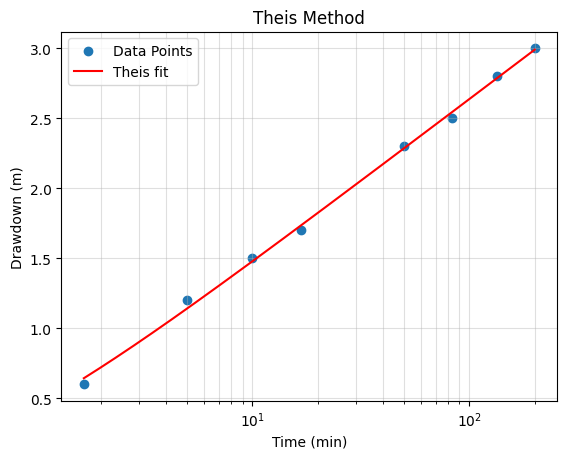

In [20]:
#Data
df = pd.DataFrame({
    'Time since pumping started (min)': [1.67,5,10,16.67,50,83.33,133.33,200],
    'Drawdown (m)': [0.6,1.2,1.5,1.7,2.3,2.5,2.8,3]
})

Q = 54 # m3/hour
r = 20 # m

t = df['Time since pumping started (min)'] / 60  # convert to hours
s_obs = df['Drawdown (m)'] 

# W(u) is the exponential integral E1
def theis(t, T, S):
    u = (r**2 * S) / (4 * T * t)
    s_est = (Q / (4 * np.pi * T)) * ssp.exp1(u)
    return s_est

# Initial guesses for T and S
p0 = [100, 1e-4]
params, _ = so.curve_fit(theis, t, s_obs, p0=p0)
T, S = params

print(f"T = {T:.3f} m2/hour")
print(f"S = {S:.3g}")

# Plot
t_fit = np.logspace(np.log10(t.min()), np.log10(t.max()), 200)
s_fit = theis(t_fit, T, S)

plt.scatter(t * 60, s_obs, label='Data Points') #convert t back to minutes for plotting
plt.plot(t_fit * 60, s_fit, color='red', label='Theis fit') #convert t_fit bakc to minutes for plotting
plt.xscale('log')
plt.xlabel('Time (min)')
plt.ylabel('Drawdown (m)')
plt.title('Theis Method')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

### Q3

Assumptions are defined and the Theis equation in 1D is solved.

A 2D grid to plot of the cone of depression from the drawdone over a contour plot is shown. 

The drawdown at the well after 3 years is 4.8 m.

The 2D contour plot visualises the cone of depression. The 1D result at r=0.1 m is the definitive answer as it evaluates the Theis equation at the exact well radius of $r=0.1$.

Max Drawdown 1D (s):4.8008 m at r=0.1 m, t=3.0 years


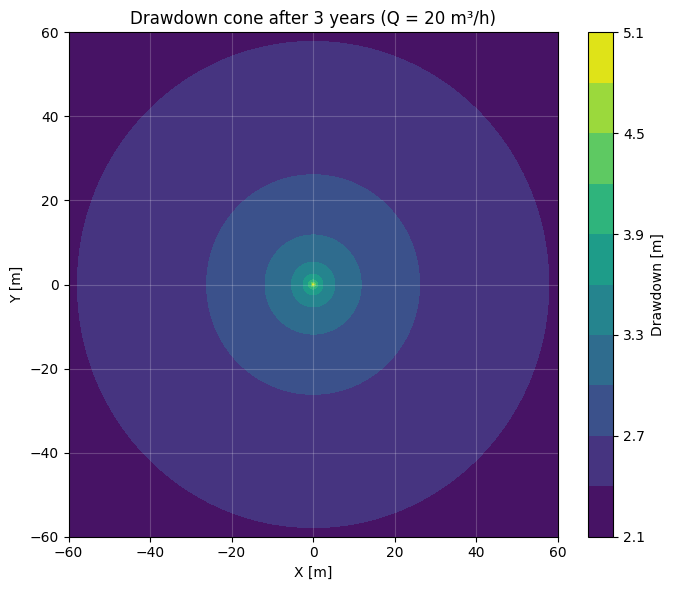

In [21]:
x_well = 1000  # m
t      = 3 * 365 * 24  # 3 years in hours
Q      = 20 # m³/hour
r      = 0.1 # m (well radius)
b      = 15 # m

# 1D
u_1d = r**2 * S / (4 * T * t)
s_1d = (Q / (4 * np.pi * T)) * float(ssp.exp1(u_1d))
print(f"Max Drawdown 1D (s):{s_1d:.4f} m at r={r} m, t={t/365/24} years")

# 2D Grid
x = np.linspace(-60, 60, 1200)
y = np.linspace(-60, 60, 1200)
X, Y = np.meshgrid(x, y)

R = np.sqrt(X**2 + Y**2)
R = np.where(R < r, r, R)  # clamp minimum to well radius

u_2d = R**2 * S / (4 * T * t)
s_2d = (Q / (4 * np.pi * T)) * ssp.exp1(u_2d)

# Plot
plt.figure(figsize=(7, 6))
plt.contourf(X, Y, s_2d, levels=8, cmap='viridis')
plt.colorbar(label='Drawdown [m]')
plt.title(f'Drawdown cone after {t/(365*24):.0f} years (Q = {Q} m³/h)')
plt.xlabel('X [m]')
plt.ylabel('Y [m]')
plt.grid(color='white', alpha=0.2)
plt.tight_layout()
plt.show()

### Q4

Assumptions are defined for both wells and the observation well. 

A 2D conotur plot is defined and the drawdown is calculated for each well using Theis equation.

Via superposition total drawdown at the observation well is calculated by adding the individual drawdown from each well:

$$ s_{total} = s_1 + s_2  $$

In [22]:
x_w1, x_w2, x_obs = 1000, 750, (1000-20) #m

t1 = 4*365*24 #hours active
t2 = 1*365*24 #hours active

Q1, Q2 = 20, 15 #m3/h

r1, r2 = 20, abs(x_obs-x_w2) #m

# Drawdown for each well
def drawdown(r, Q, t):
    u = r**2 * S / (4 * T * t)
    return (Q / (4 * np.pi * T)) * ssp.exp1(u)

s1 = drawdown(r1, Q1, t1)
s2 = drawdown(r2, Q2, t2)

s_tot = s1 + s2

print(f"Drawdown from Well 1: {s1:.3f} m")
print(f"Drawdown from Well 2: {s2:.3f} m")
print(f"Superposition of drawdowns: {s_tot:.3f} m")

Drawdown from Well 1: 2.855 m
Drawdown from Well 2: 1.254 m
Superposition of drawdowns: 4.109 m


### Q5

Assumptions and the expression for the hydraulic head from Q1 is defined.

Each well is given a location withing the 2D plot.

A 2D meshgrid is created and the distance from each well to each point in the domain is computed using pythagoras theorem.

The Theis equation is used to calculate drawdown as before.

Total head is found with superposition of the drawdown from both wells for all points.
$$ H = h_0 - s_1 - s_2 $$

Plot is created with shown wells and observation well.

It should be noted that an assumptions of the Theis equation are that the aquifer is inifite and confined. This causes the head levels $h(0)=29.6$ and $h(2400)=23.2$. In reality the head level of the rivers on each side could provide constant head boundaries and recharge the aquifer, however no assumtions of the rivers are defined and this is therefore ignored in the calculation.

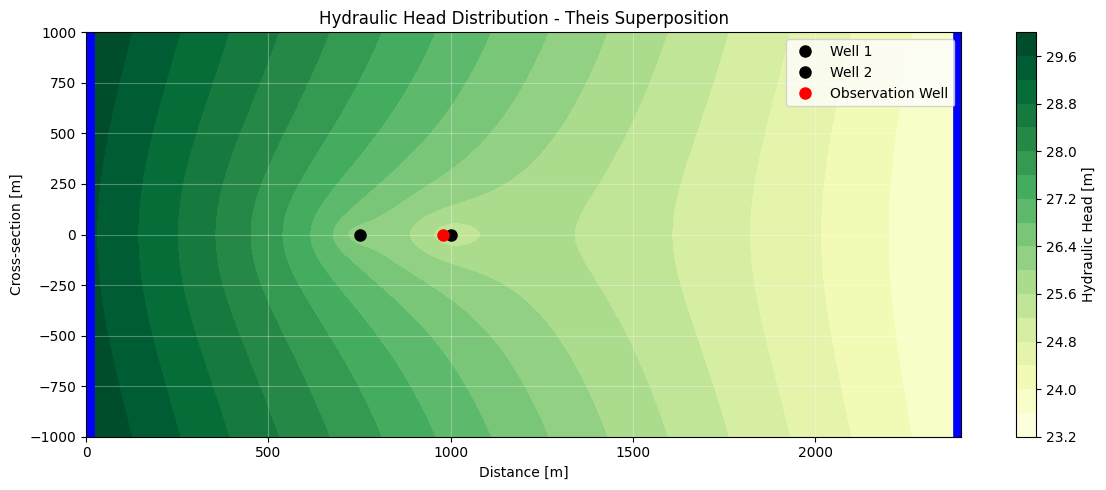

In [23]:
x_w1, x_w2, x_obs = 1000, 750, (1000-20) #m

t1 = 4*365*24 #hours active
t2 = 1*365*24 #hours active

Q1, Q2 = 20, 15 #m3/h

well1 = (x_w1, 0)
well2 = (x_w2, 0)
obs_well = (980,0) #m

# 2D Grid
nx, ny = 200, 100
x = np.linspace(0, 2400, nx)
y = np.linspace(-1000, 1000, ny)
X, Y = np.meshgrid(x, y)

h0 = float(c1)*X + float(c2)

# Radial distances from each well
r1 = np.sqrt((X - well1[0])**2 + (Y - well1[1])**2)
r2 = np.sqrt((X - well2[0])**2 + (Y - well2[1])**2)
r1 = np.maximum(r1, 1)   # avoid log(0) at well location
r2 = np.maximum(r2, 1)

# Drawdown for each well
def drawdown(r, Q, t_active):
    u = r**2 * S / (4 * T * t_active)
    return (Q / (4 * np.pi * T)) * ssp.exp1(u)

s1 = drawdown(r1, Q1, t1)
s2 = drawdown(r2, Q2, t2)

# Total head (superposition)
H = h0 - s1 - s2

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

cf = ax.contourf(X, Y, H, levels=20, cmap='YlGn')
plt.colorbar(cf, ax=ax, label='Hydraulic Head [m]')

# River boundaries (blue bars)
ax.axvline(0,    color='blue', linewidth=12)
ax.axvline(2400, color='blue', linewidth=12)

# Well locations
ax.plot(*well1, 'ko', markersize=8, label='Well 1')
ax.plot(*well2, 'ko', markersize=8, label='Well 2')
ax.plot(*obs_well, 'ro', markersize=8, label='Observation Well')

ax.set_xlabel('Distance [m]')
ax.set_ylabel('Cross-section [m]')
ax.set_title('Hydraulic Head Distribution - Theis Superposition')
ax.grid(True, color='white', alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Streamlines are added by first computing the hydraulic gradient components 
using `np.gradient` with the hydraulic head $H$ and the $x$, $y$ coordinates:

$$\frac{\partial h}{\partial x}, \quad \frac{\partial h}{\partial y}$$

The hydraulic conductivity is then derived from the transmissivity:
$$K = \frac{T}{b}$$

This is used to compute the specific discharge components via Darcy's law:
$$q_x = -K \frac{\partial h}{\partial x}, \quad q_y = -K \frac{\partial h}{\partial y}$$

Finally, `ax.streamplot` is called with the $x$, $y$ coordinate arrays and 
the specific discharge components $q_x$ and $q_y$ to create the flow paths of the streamlines across the domain.

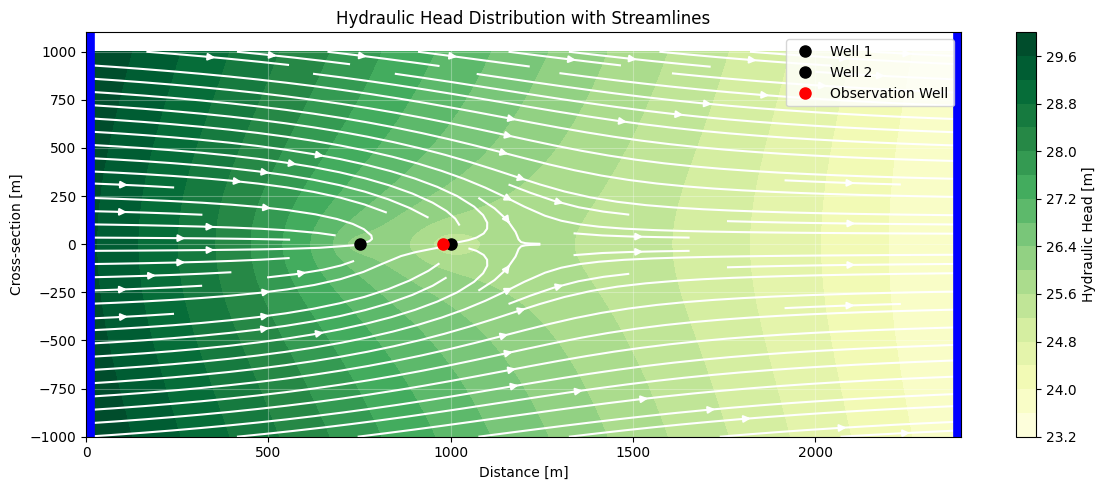

In [24]:
# Hydraulic gradient
K = T / b # m/hour
grad_y, grad_x = np.gradient(H, y, x)

# Specific discharge
qx = -K * grad_x
qy = -K * grad_y

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

cf = ax.contourf(X, Y, H, levels=20, cmap='YlGn')
plt.colorbar(cf, ax=ax, label='Hydraulic Head [m]')

# Streamlines
ax.streamplot(x, y, qx, qy, color='w')

# River boundaries (blue bars)
ax.axvline(0,    color='blue', linewidth=12)
ax.axvline(2400, color='blue', linewidth=12)

# Well locations
ax.plot(*well1, 'ko', markersize=8, label='Well 1')
ax.plot(*well2, 'ko', markersize=8, label='Well 2')
ax.plot(*obs_well, 'ro', markersize=8, label='Observation Well')

ax.set_xlabel('Distance [m]')
ax.set_ylabel('Cross-section [m]')
ax.set_title('Hydraulic Head Distribution with Streamlines')
ax.grid(True, color='white', alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Q6

WIth provided assumptions maximum extraction rate of well 2 ($Q_2$) the Theis equation is used as before to find the drawdown from well 1 ($s_1$). From this the drawdown budget of well 2 ios calculated as the difference between the head level change within the limit and $s_1$:
$$s_{budget} = (32-30) - s_1$$

From this $Q_2$ may be solved:
$$Q_{2,max} = s_{budget} \frac{4 \pi T}{W_2} $$

In [25]:
r1 = 1000 # m
r2 = 750 # m

t1 = 5 * 365 * 24 # hours
t2 = 1 * 365 * 24 # hours

Q1 = 15 # m³/hour

# Drawdown function
def drawdown(r, Q, t_active):
    u = r**2 * S / (4 * T * t_active)
    s = (Q / (4 * np.pi * T)) * ssp.exp1(u)
    return s

# Drawdown at x=0 from well 1
s1_river = drawdown(r1, Q1, t1)

# Maximum drawdown by well 2
s_limit = 32.0 - 30.0
s2_budget = s_limit - s1_river

# Solve for Q2
u2 = r2**2 * S / (4 * T * t2)
W2 = float(ssp.exp1(u2))

Q2_max = s2_budget * (4 * np.pi * T) / W2

print(f"Drawdown at river from well 1: {s1_river:.3f} m")
print(f"Maximum drawdown for well 2:   {s2_budget:.3f} m")
print(f"Maximum Q2:                    {Q2_max:.2f} m³/hour")

Drawdown at river from well 1: 1.065 m
Maximum drawdown for well 2:   0.935 m
Maximum Q2:                    15.25 m³/hour


# Part C

### Q1

The code imports data for the borehole, containing the drawdown data, as well as the coordinates. The code further defines a starting and stopping time for the pumping, and plots the different observational wells, together with their distance to the pumping well, their vertical screen and screen top. The plots created are ranked in ascending order, from closest to the pumping well, to furthest away. The plots show a dotted red line when the pumping starts and stops, and the blue line matches the drawdown data, minus the rest water level, to normalize the drawdown data to zero.

Q3 will delve deeper into the subject of the geographical nature of the observational wells, and what that means for usage of the Theis solution.

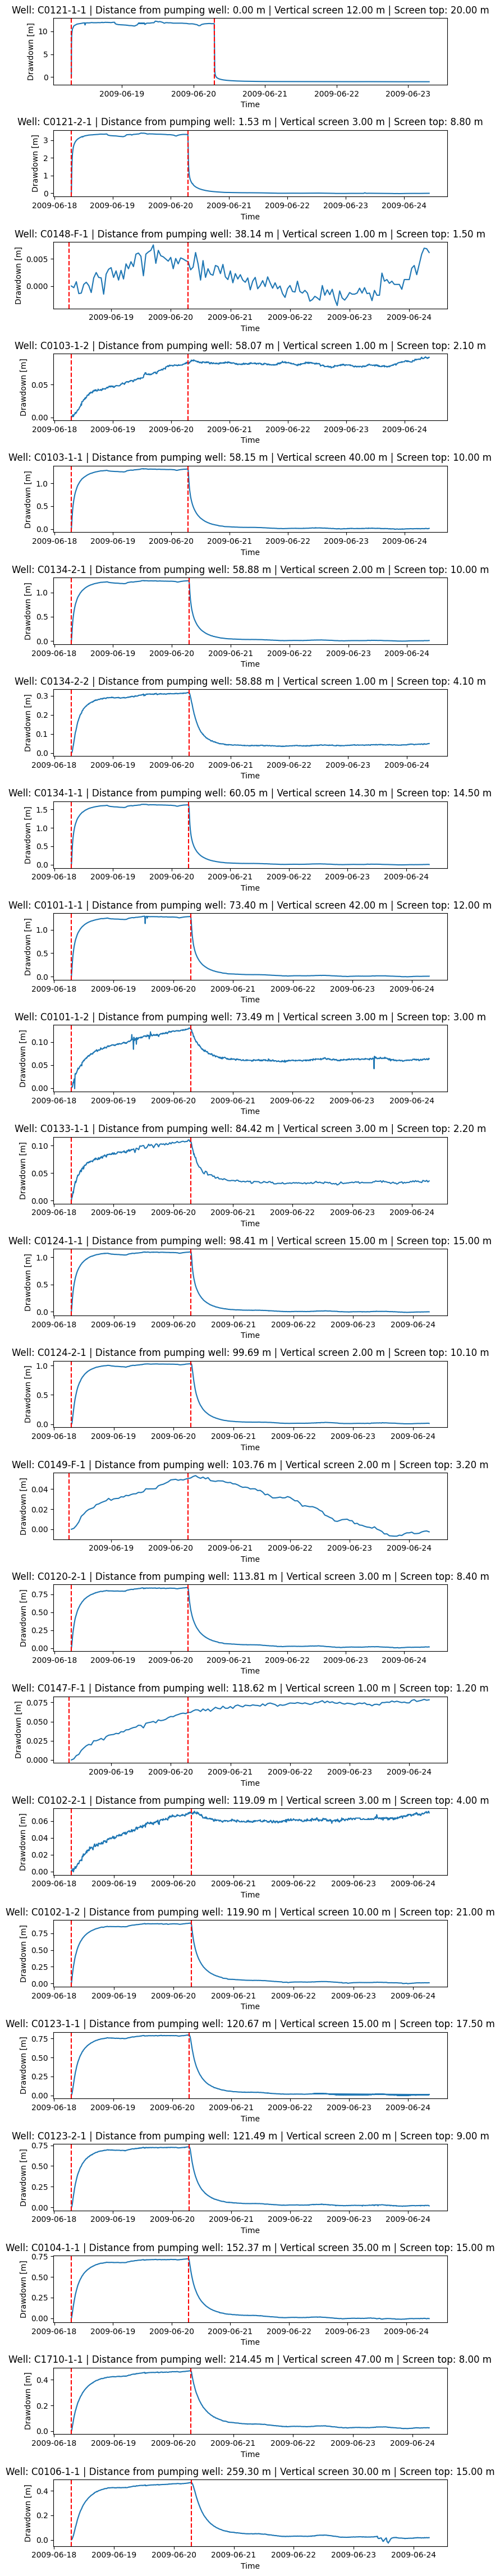

In [26]:
# Load data
data = pd.read_excel(r'C0121.xlsx', 'Drawdown Data') #Read the Drawdown Data sheet
bhdetails = pd.read_excel(r'C0121.xlsx', 'Borehole Coordinates') #Read the Borehole Coords sheet

pump_start = pd.to_datetime("2009-06-18 07:01:00") 
pump_stop = pd.to_datetime("2009-06-20 07:01:00")

#In order to plot the wells in the order of increasing distrance from pumping well, the dataframe bhdetails, is sorted by distance. 
bhdetails_sort = bhdetails.sort_values(by = ['Distance from pumping well [m]']).reset_index(drop=True)

# Setup subplots
n_boreholes = len(bhdetails_sort)
fig, axs = plt.subplots(n_boreholes, 1, figsize=(8, 2 * n_boreholes), sharex=False)
if n_boreholes == 1:
    axs = [axs] # Ensure axes is iterable
    
# Plot each borehole's data
for i, ax in enumerate(axs):
    name = bhdetails_sort['Name'][i]

    tstring = f'Time {name}' # time string extrcting time data from excel
    ddstring = f'Drawdown {name} (mbs)' # drawdown string, exstracting drawdown time from excel.
    rwl = bhdetails_sort['Rest water level (m below surface, mbs)'][i] # used to normalize drawdown data to zero. 

    distance = bhdetails_sort['Distance from pumping well [m]'][i]

    screen_top = bhdetails_sort['Screen Top [m]'][i]
    screen_bottom = bhdetails_sort['Screen Bottom [m]'][i]
    screen_length = screen_bottom-screen_top
        
    ax.plot(data[tstring], data[ddstring] - rwl) #plot the data
    ax.axvline(pump_start, color='red', linestyle='--') # plot pump start vertical line
    ax.axvline(pump_stop, color='red', linestyle='--') # plot pump stop vertical line


    ax.set_xlabel('Time')
    ax.set_ylabel('Drawdown [m]')
    ax.set_title(f'Well: {name} | Distance from pumping well: {distance:.2f} m | Vertical screen {screen_length:.2f} m | Screen top: {screen_top:.2f} m')

plt.tight_layout()
plt.show()


### Q2

We've reused the Theis solution from tutorial 3, with variables as described in the function itself. Several useful constants have also been saved, to be used moving further in part C. Only looking at the observational wells, the list is sorted for these. Afterwards the assumed Theis solution is applied, and plotted together with the graphs from question 1. Only looking at the drawdown period, for the duration the pump is running, the recovering of the wells after the duration is not considered. 

In [27]:
#Constants to be used moving forward
T = 0.001 #transmissivity (m2/s)
S = 5*10**(-5) #Storativity 
Q_h = 9 #flow rate (m3/h)
Q_s = Q_h/(60*60) #flow rate (m3/s)
t_h = 48 #hours
t_s = t_h*60*60 #hours to seconds
#display(Q_h,Q_s,t_h,t_s,S, t_s/3600)

$$s(r,t) = \frac{Q}{4\pi T} W(u)$$

$$u = \frac{r^2 S}{4Tt}$$

$$W(u) = \int_u^\infty \frac{e^{-u}}{u} \, du$$

where: 
- r is the radial distance from the pumping well to the measuring point. This value, can for each well be extracted from the excel sheet "C0121.xlsx" under the fane "Borehole Coordinates"
- t is the time. In our case, the time is the 48 hour pump period.
- Q is the flow rate. Which is 9 m3/h


In [28]:
#Theis solution returns the drawdown level at a certain time. 
def Theis_solution(t, r, Q, T, S):
    """
    Objective:
    Parameters:
    -----------
    r: float [m]
        radial distance from pumping well to observation well
    T: float [m2/s]
        Transmissivity
    S: float [unitless]
        Storativity
    Q: float [m3/s]
        Pumping rate
    t: ndarray [s]
        Time 
    
    Returns: 
    --------
    s: ndarray [m]
        Drawdown
    """
    
    u = ((r**2)*S)/(4*T*t)
    s = (Q/(4*np.pi*T))*exp1(u) #s = drawdown
    return s

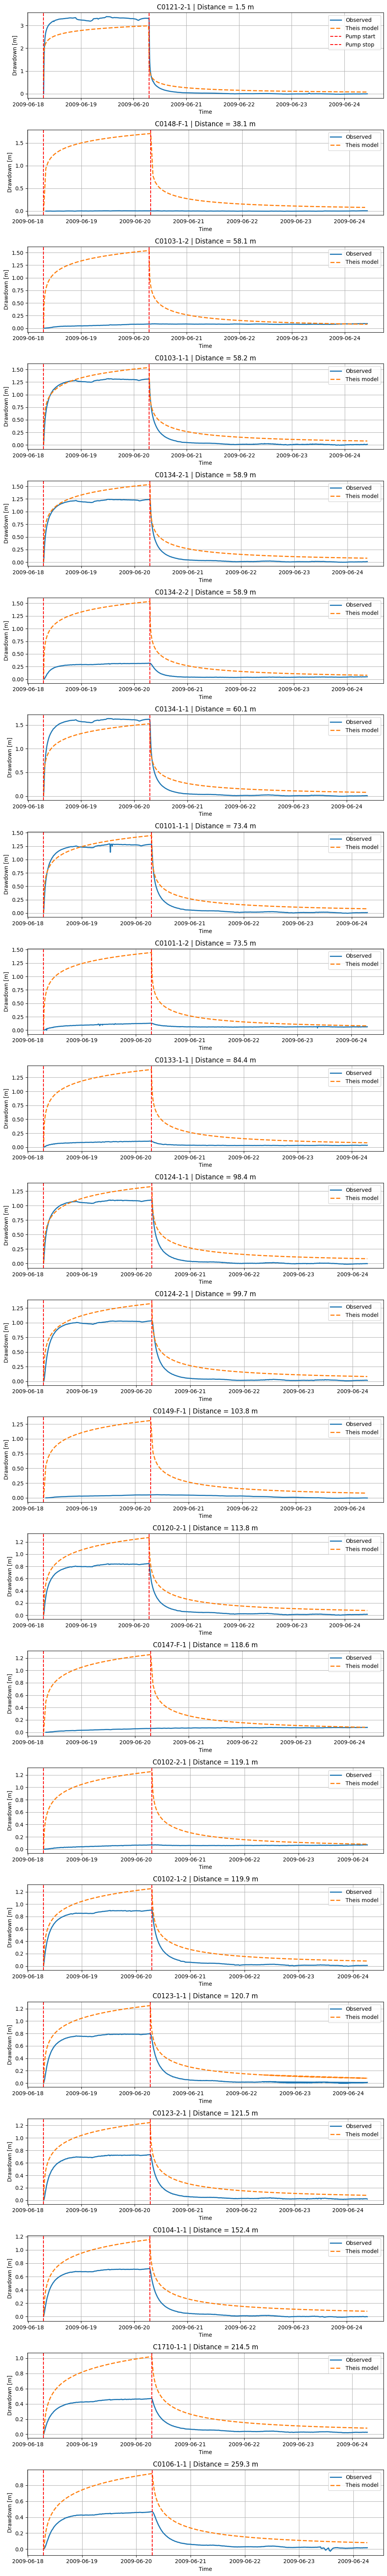

In [29]:
bhdetails_obs_well_sort = bhdetails_sort[bhdetails_sort['Well type'] == 'Obs. well']

# ---------------------------
# PLOTTING
# ---------------------------
pump_start = pd.to_datetime("2009-06-18 07:01:00")
pump_stop = pd.to_datetime("2009-06-20 07:01:00")

n_boreholes = len(bhdetails_obs_well_sort)

fig, axs = plt.subplots(n_boreholes, 1, figsize=(10, 3 * n_boreholes), sharex=False)

if n_boreholes == 1:
    axs = [axs]

for i, ax in enumerate(axs):

    # --- GET DATA ---
    row = bhdetails_obs_well_sort.iloc[i]
    name = row['Name']
    distance = row['Distance from pumping well [m]']

    tstring = f'Time {name}'
    ddstring = f'Drawdown {name} (mbs)'

    rwl = row['Rest water level (m below surface, mbs)']

    # --- OBSERVED DATA ---
    obs_time = pd.to_datetime(data[tstring], errors='coerce')
    obs_dd = pd.to_numeric(data[ddstring], errors='coerce') - rwl
    valid = obs_time.notna() & obs_dd.notna()

    ax.plot(
        obs_time[valid],
        obs_dd[valid],
        label='Observed',
        linewidth=2
    )

    # --- THEIS MODEL ---
    time_sec = (obs_time[valid] - obs_time[valid].iloc[0]).dt.total_seconds().to_numpy()
    time_sec = np.maximum(time_sec, 1)

    t_pump_off = 48 * 60 * 60

    t_after = time_sec - t_pump_off
    t_after_safe = t_after.copy()
    t_after_safe[t_after_safe <= 0] = 1

    drawdown_model_1 = Theis_solution(time_sec, distance, Q_s, T, S)
    drawdown_model_2 = Theis_solution(t_after_safe, distance, Q_s, T, S)
    drawdown_model_2[time_sec < t_pump_off] = 0

    drawdown_model_total = drawdown_model_1 - drawdown_model_2

    model_time = pump_start + pd.to_timedelta(time_sec.astype(int), unit='s')

    ax.plot(
        model_time,
        drawdown_model_total,
        '--',
        label='Theis model',
        linewidth=2
    )

    # --- PUMP PERIOD ---
    ax.axvline(pump_start, color='red', linestyle='--', label='Pump start' if i == 0 else "")
    ax.axvline(pump_stop, color='red', linestyle='--', label='Pump stop' if i == 0 else "")

    # --- LABELS ---
    ax.set_title(f'{name} | Distance = {distance:.1f} m')
    ax.set_xlabel('Time')
    ax.set_ylabel('Drawdown [m]')
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

### Q3

Criterias used to determine unusable wells include the following assumptions:
- Wells with no recovery after pump stop $\rightarrow$ unconfined or not hydraulically connected
- Wells with screen above rest water level $\rightarrow$ partially penetrating
- Wells with thin or absent clay above screen $\rightarrow$ leakage violates confinement

| Well type | Name       | Status | Comment                                                                 | Distance [m] | Screen Top [m] | Screen Bottom [m] | Rest water level (mbs) |
|-----------|------------|--------|-------------------------------------------------------------------------|--------------|----------------|-------------------|------------------------|
| Obs. well | C0121-2-1  | Yes    |                                                                         | 2            | 8.8            | 11.8              | 2.53                   |
| Obs. well | C0148-F-1  | No     | Partial penetration, water level lower than screen top                  | 38           | 1.5            | 2.5               | 2.09                   |
| Obs. well | C0103-1-2  | No     | Unconfined – no clay layer above screen                                 | 58           | 2.1            | 3.1               | 1.57                   |
| Obs. well | C0103-1-1  | Yes    |                                                                         | 58           | 10             | 50                | 2.30                   |
| Obs. well | C0134-2-1  | Yes    |                                                                         | 59           | 10             | 12                | 2.63                   |
| Obs. well | C0134-2-2  | No     | Thin clay layer; screen partly in clay → leakage                        | 59           | 4.1            | 5.1               | 2.10                   |
| Obs. well | C0134-1-1  | Yes    |                                                                         | 60           | 14.5           | 28.8              | 2.48                   |
| Obs. well | C0101-1-1  | Yes    |                                                                         | 73           | 12             | 54                | 1.95                   |
| Obs. well | C0101-1-2  | No     | Unconfined – thin clay layer above screen                               | 73           | 3              | 6                 | 1.55                   |
| Obs. well | C0133-1-1  | No     | Partial penetration, water level lower than screen top                  | 84           | 2.2            | 5.2               | 2.25                   |
| Obs. well | C0124-1-1  | Yes    |                                                                         | 98           | 15             | 30                | 2.68                   |
| Obs. well | C0124-2-1  | Yes    |                                                                         | 100          | 10.1           | 12.1              | 2.70                   |
| Obs. well | C0149-F-1  | No     | Unconfined                                                              | 104          | 3.2            | 5.2               | 1.58                   |
| Obs. well | C0120-2-1  | Yes    |                                                                         | 114          | 8.4            | 11.4              | 2.28                   |
| Obs. well | C0147-F-1  | No     | Partial penetration, water level lower than screen top                  | 119          | 1.2            | 2.2               | 1.83                   |
| Obs. well | C0102-2-1  | No     | Unconfined – no clay layer above screen                                 | 119          | 4              | 7                 | 1.12                   |
| Obs. well | C0102-1-2  | Yes    |                                                                         | 120          | 21             | 31                | 1.75                   |
| Obs. well | C0123-1-1  | No    | Not confined – no clay above limestone                                  | 121          | 17.5           | 32.5              | 2.40                   |
| Obs. well | C0123-2-1  | Yes    |                                                                         | 121          | 9              | 11                | 2.39                   |
| Obs. well | C0104-1-1  | Yes    |                                                                         | 152          | 15             | 50                | 2.65                   |
| Obs. well | C1710-1-1  | Yes    |                                                                         | 214          | 8              | 55                | 2.17                   |
| Obs. well | C0106-1-1  | Yes    |                                                                         | 259          | 15             | 45                | 2.84                   |

The pump test data from the observation wells; C0102-2-1, C0103-1-2, C0147-F-1, C0148-F-1 and C0149-F-1 shows sign of the wells being unconfined. Looking at the borehole profiles it can for C0102-2-1 and C0103-1-2 be concluded that the filter i set in an unconfined aquifer. For the rest of the wells, the boreprofile is not found, but the data on the borehole is short which suggest that the wells are also unconfined. Which is one of the prerequsite for the Theis solution being valid. 

selected_wells = [
    "C0121-2-1",
    "C0106-1-1"
    "C0103-1-1",
    "C0134-2-1",
    "C0134-1-1",
    "C0101-1-1",
    "C0124-1-1",
    "C0124-2-1",
    "C0120-2-1",
    "C0102-1-2",
    "C0123-2-1",
    "C0104-1-1",
    "C1710-1-1",
    "C0106-1-1",
]


Not working: 
    C0148-F-1
    C0103-1-2
    C0134-2-2
    "C0101-1-2",
    "C0133-1-1",
    "C0149-F-1",
    "C0147-F-1",
    "C0102-2-1",
    "C0123-1-1"

### Q4

On the basis of Q3, suitable observational wells have been selected for further fitting. The 4 nearest observational wells have further been used as the main drivers for the visual guesses, for the transmissivity and the storativity. The initial guesses, and Theis solution, has been plotted together with the new guesses and Theis solution, to show their how he new guesses better fits the data from the 4 nearest observational wells.
The solution fits the closest 2 wells, "C0103-1-1" and "C0134-2-1" closely, undershoots a bit on "C0134-1-1", while also matching quite well on "C0101-1-1", as displayed in the graphs as the green dotted line compared to the initial assumptions.

The optimal transmissivity is guessed as 1.35e-03, and optimal storativity as 1.2e-05.

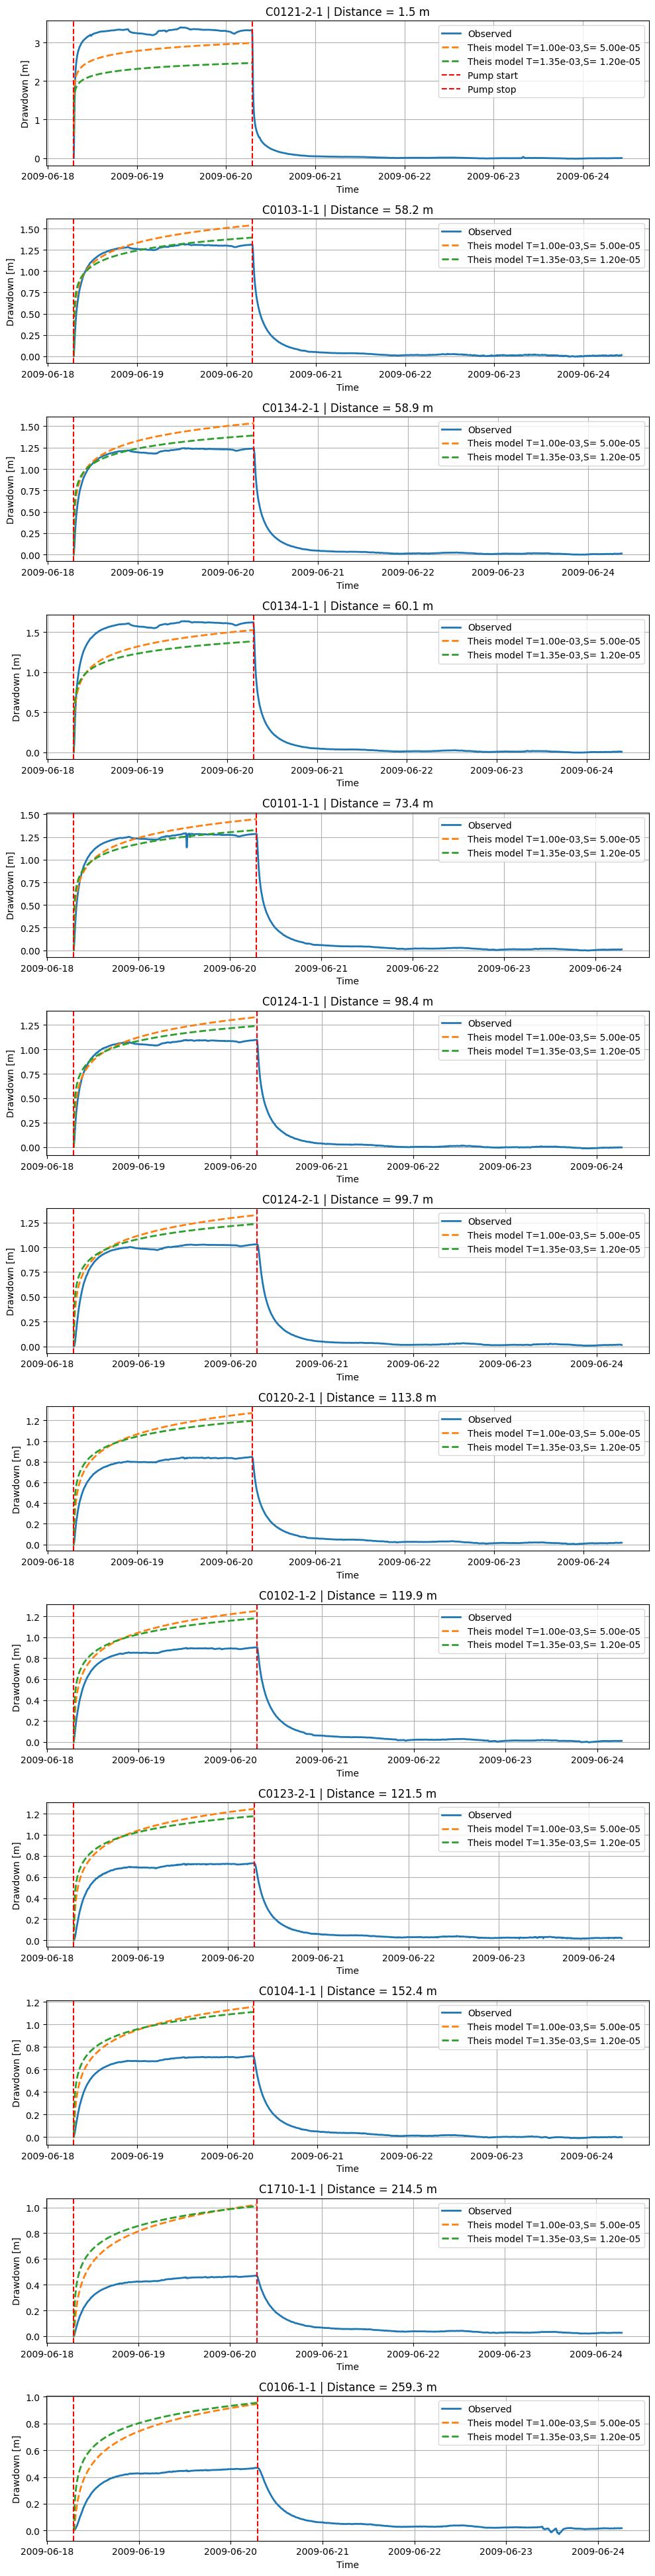

In [30]:
#Make new guesses for T and S based on the previous plot.
T_opt = 1.35e-03 #Guess for transmissivity for mid-distance wells
S_opt = 1.2e-05 #Guess for storativity for mid-distance wells

selected_wells = [
    "C0121-2-1",
    "C0103-1-1",
    "C0134-2-1",
    "C0134-1-1",
    "C0101-1-1",
    "C0124-1-1",
    "C0124-2-1",
    "C0120-2-1",
    "C0102-1-2",
    "C0123-2-1",
    "C0104-1-1",
    "C1710-1-1",
    "C0106-1-1",
]

# Time for model (avoid t=0)
t = np.linspace(1, t_s, 1000)

# ---------------------------
# PLOTTING
# ---------------------------
n_boreholes = len(selected_wells)

fig, axs = plt.subplots(n_boreholes, 1, figsize=(10, 3 * n_boreholes), sharex=False)

if n_boreholes == 1:
    axs = [axs]

for i, ax in enumerate(axs):
    
    name = selected_wells[i]
    well = bhdetails_sort[bhdetails_sort["Name"] == name]
        
    radius = float(well['Distance from pumping well [m]'].iloc[0])
    rwl = float(well['Rest water level (m below surface, mbs)'].iloc[0])
    
    tstring = f"Time {name}" # time string extrcting time data from excel
    ddstring = f"Drawdown {name} (mbs)" # drawdown string, exstracting drawdown time from excel.


        # --- OBSERVED DATA ---
    ax.plot(data[tstring],
            data[ddstring] - rwl,
            label='Observed',
            linewidth=2)
    
        # --- THEIS MODEL ---
    drawdown_model = Theis_solution(t, radius, Q_s, T, S)
    drawdown_model_opt = Theis_solution(t, radius, Q_s, T_opt, S_opt)
        
        # convert model time to datetime
    model_time = pump_start + pd.to_timedelta(t, unit='s')
    
    ax.plot(model_time,
            drawdown_model,
            '--',
            label=f'Theis model T={T:.2e},S= {S:.2e}',
            linewidth=2)

    ax.plot(model_time,
            drawdown_model_opt,
            '--',
            label=f'Theis model T={T_opt:.2e},S= {S_opt:.2e}',
            linewidth=2)

    # --- PUMP PERIOD ---
    ax.axvline(pump_start, color='red', linestyle='--', label='Pump start' if i == 0 else "")
    ax.axvline(pump_stop, color='red', linestyle='--', label='Pump stop' if i == 0 else "")
    
        # --- LABELS ---
    ax.set_title(f'{name} | Distance = {radius:.1f} m')
    ax.set_xlabel('Time')
    ax.set_ylabel('Drawdown [m]')
    ax.grid(True)
    ax.legend()

# ---------------------------
# FINAL TOUCH
# ---------------------------
plt.tight_layout()
plt.show()

### Q5

The Theis solution uses several assumptions, that does not translate 1:1 into a real world scenario, which is why some wells have been discarded, and also why we finally choose the close wells as the basis of the fitting. 

Where the Theis curve fits poorly may explained by the following:
- Early time deviation — Theis assumes instantaneous response but the aquifers have borewell storage effects in the beginning, causing observed drawdown to lag behind the model.

- Late time deviation — if observed drawdown flattens out more than model predicts, it suggests recharge from a boundary that Theis doesn't account for.

- Recovery phase — if observed recovery is slower than modelled, it suggests the aquifer isn't perfectly homogeneous or there are boundary effects.

- General Limitations - The aquifers in Copenhagen is heterogenerous which violates the Theis assumtion of an homogenous isotropic infite aquifer.

An attempt to optimize the Theis equation would be to restrict the pumping phase to only fit in the time between pumping starts and stops instead of the whole test period such that 
``m = (t >= 0) & (t <= tp)``.

Additonally, a weighting by borehole distance to observation well would avoid skewing from nearby wells for a better general fit across wells. A simple setup is proposed below by indexing the distances `weight = 1.0 / r`.

T = 6.348e-04 m²/s
S = 1.039e-03


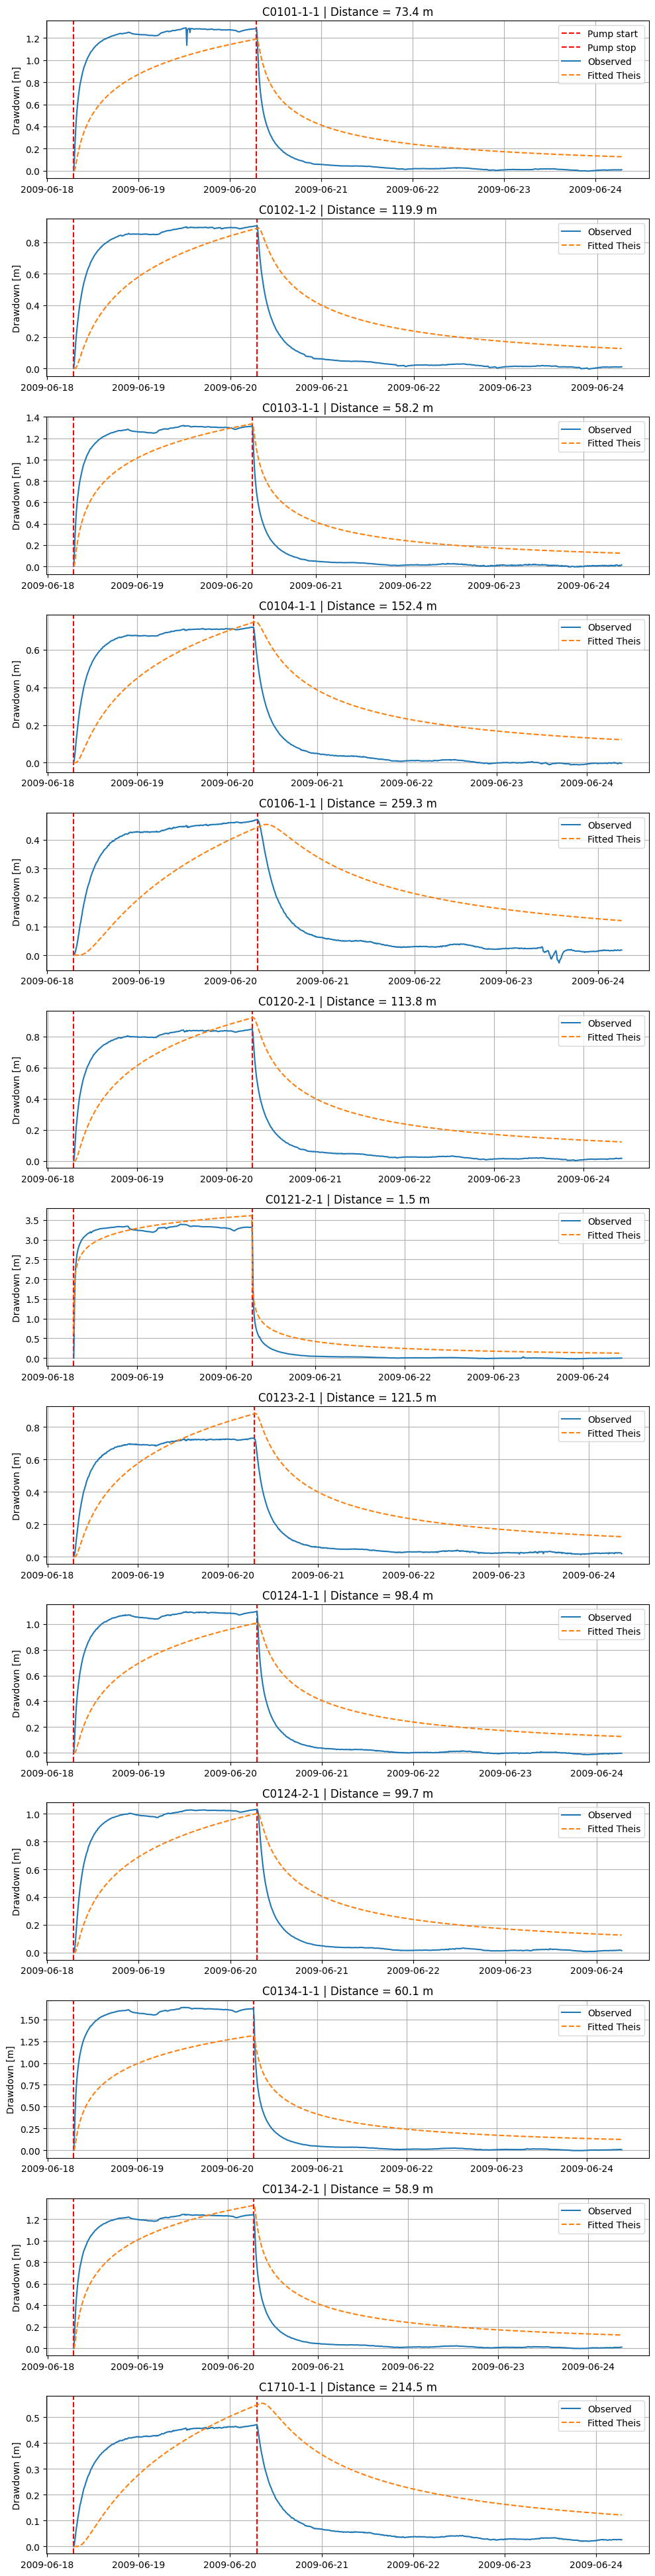

In [31]:
# --------------------------
# Theis function
# --------------------------
def theis(Q, T, S, r, t):
    t = np.maximum(np.asarray(t, dtype=float), 1e-10)
    u = r**2 * S / (4 * T * t)
    return Q / (4 * np.pi * T) * exp1(u)

def theis_full(Q, T, S, r, t, tp):
    s = theis(Q, T, S, r, t)
    after = t > tp
    s[after] = theis(Q, T, S, r, t[after]) - theis(Q, T, S, r, t[after] - tp)
    return s

# --------------------------
# Load data
# --------------------------

for col in data.columns:
    if str(col).startswith("Time "):
        data[col] = pd.to_datetime(data[col], errors="coerce", dayfirst=True)

bhdetails = bhdetails[
    bhdetails["Well type"].str.contains("Obs", case=False, na=False)
].copy().reset_index(drop=True)

# --------------------------
# Select usable wells from Q3
# --------------------------
usable_wells = [
    "C0121-2-1",
    "C0103-1-1",
    "C0134-2-1",
    "C0134-1-1",
    "C0101-1-1",
    "C0124-1-1",
    "C0124-2-1",
    "C0120-2-1",
    "C0102-1-2",
    "C0123-2-1",
    "C0104-1-1",
    "C1710-1-1",
    "C0106-1-1",
]

bhdetails["Theis"] = bhdetails["Name"].isin(usable_wells).astype(int)

# --------------------------
# Test settings
# --------------------------
Q = 9.0 / 3600
pump_start = pd.Timestamp("2009-06-18 07:01:00")
pump_stop  = pd.Timestamp("2009-06-20 07:01:00")
tp = (pump_stop - pump_start).total_seconds()

def residuals(p):
    T, S = p
    res = []

    for i in range(len(bhdetails)):
        if not bhdetails.loc[i, "Theis"]:
            continue

        name = bhdetails.loc[i, "Name"]
        r = bhdetails.loc[i, "Distance from pumping well [m]"]
        rwl = bhdetails.loc[i, "Rest water level (m below surface, mbs)"]

        t = data[f"Time {name}"]
        s_obs = pd.to_numeric(data[f"Drawdown {name} (mbs)"], errors="coerce") - rwl

        m = t.notna() & s_obs.notna()
        t = (t[m] - pump_start).dt.total_seconds()
        s_obs = s_obs[m]

        # Only use pumping phase
        m = (t >= 0) & (t <= tp)
        t = t[m].to_numpy()
        s_obs = s_obs[m].to_numpy()

        if len(t) == 0:
            continue

        s_sim = theis_full(Q, T, S, r, t, tp)

        # Weight by 1/distance — distant wells get equal importance
        weight = 1.0 / r
        res.extend(weight * (s_sim - s_obs))

    return np.array(res)

# --------------------------
# Fit T and S
# --------------------------
fit = so.least_squares(residuals, x0=[1e-3, 1e-5], bounds=([1e-6, 1e-8], [1e-1, 1e-1]))
T_best, S_best = fit.x

print(f"T = {T_best:.3e} m²/s")
print(f"S = {S_best:.3e}")

# --------------------------
# Plot fitted curves
# --------------------------
selected = bhdetails[bhdetails["Theis"] == 1].reset_index(drop=True)

fig, axs = plt.subplots(len(selected), 1, figsize=(10, 3*len(selected)))
if len(selected) == 1:
    axs = [axs]

for i, ax in enumerate(axs):
    name = selected.loc[i, "Name"]
    r = selected.loc[i, "Distance from pumping well [m]"]
    rwl = selected.loc[i, "Rest water level (m below surface, mbs)"]

    t = data[f"Time {name}"]
    s_obs = pd.to_numeric(data[f"Drawdown {name} (mbs)"], errors="coerce") - rwl

    m = t.notna() & s_obs.notna()
    t_plot = t[m]
    t_sec = (t_plot - pump_start).dt.total_seconds()
    s_obs = s_obs[m]

    m = t_sec >= 0
    t_plot = t_plot[m]
    t_sec = t_sec[m].to_numpy()
    s_obs = s_obs[m].to_numpy()

    s_fit = theis_full(Q, T_best, S_best, r, t_sec, tp)

# --- PUMP PERIOD ---
    ax.axvline(pump_start, color='red', linestyle='--', label='Pump start' if i == 0 else "")
    ax.axvline(pump_stop, color='red', linestyle='--', label='Pump stop' if i == 0 else "")


    ax.plot(t_plot, s_obs, label="Observed")
    ax.plot(t_plot, s_fit, "--", label="Fitted Theis")
    ax.set_title(f'{name} | Distance = {r:.1f} m')
    ax.set_ylabel("Drawdown [m]")
    ax.grid(True)
    ax.legend()


plt.tight_layout()
plt.show()


The guess approach better follows the curve of observed data with less lag in and generally overestimates drawdown for wells at greater distance. This provides a saftey principle with a margin of error which should be accounted for in the surrounding area for foundational protection parameters of nearby structures.

The optimized approach attempts to better fit the peak drawdown, however it does not project accurate drawdown development in either increase after pumping starts or recharge after pumping stops, and is thereby a general bad fit of the observed data.

In the following calculations of this notebook the transmissitivty and storativity  from the guess approach is therefore used.

### Q6

To lower the groundwater level from 2 m to 10 m below surface, a drawdown of 8 m is required. The pumping well is placed at the center of the 10 m × 10 m area, so the critical points are the corners. The distance from the well to any corner is

$$
r = \sqrt{5^2 + 5^2} = 7.07\ \text{m}
$$

Using the aquifer parameters determined in Q4 and a pumping duration of 1 day, the required pumping rate Q can be calculated using the Theis solution.

In [32]:
#Dewatering of a 10 m x 10 m construction site with a pumping well in the center

## Ændrer T og S til de optimale værdier fundet i forrige opgave

T = T_opt        # Transmissivity [m²/s]
S = S_opt      # Storativity [-]
t = 1 * 24 * 3600  # Pumping time: 1 day [s]

building_side = 10.0  # [m]
r_corner = np.sqrt((building_side/2)**2 + (building_side/2)**2)  # Distance from center to corners
drawdown_required = 8.0  # Required drawdown at corners [m]

# First calculate u at the cornor distance
u_cornor = (r_corner**2 * S) / (4 * T * t)

# Calculate the Theis well function W(u) at the corner
W_u_cornor = exp1(u_cornor)

# Solve for Q in m³/s
Q_m3s = (4 * np.pi * T * drawdown_required) / W_u_cornor

print(f"Required pumping rate: {Q_m3s:.3e} m³/s")
print(f"Required pumping rate: {Q_m3s*60:.3f} m³/min")


Required pumping rate: 1.045e-02 m³/s
Required pumping rate: 0.627 m³/min


To achieve the required dewatering of the 10 m × 10 m construction site to 10 m below surface (8 m drawdown) within one day using a single pumping well at the center, the necessary pumping rate is 0.0105 m³/s corresponding to 0.63 m³/min

### Q7

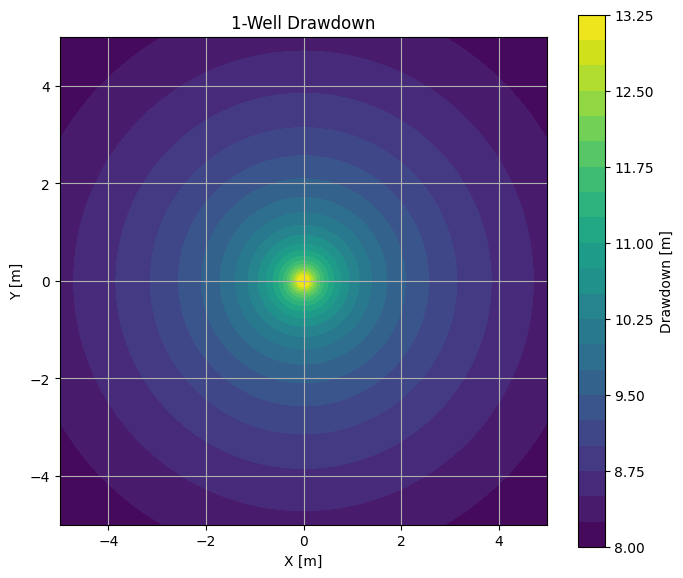

In [33]:
#required_Q is from your answer in question 6
required_Q = Q_m3s

# Grid for contour plot
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
xi, yi = np.meshgrid(x, y)
# Compute radial distance and drawdown
r = np.sqrt(xi**2 + yi**2)
r = np.maximum(r, 0.1)
dd = Theis_solution(t, r, required_Q, T, S)
# Plotting
fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contourf(xi, yi, dd, levels=20, cmap='viridis')
ax.set_title('1-Well Drawdown')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_aspect('equal')
ax.grid(True)
fig.colorbar(cs, ax=ax, label='Drawdown [m]')
plt.tight_layout()
plt.show()

The contour plot shows a circular drawdown pattern centered on the pumping well. Drawdown decreases with increasing distance from the well, forming concentric rings. At the well location, drawdown is highest, while at the corners of the construction site the drawdown reaches exactly 8.0 m as required. The entire 10 m × 10 m area achieves at least 8 m of drawdown, confirming that the calculated pumping rate successfully dewaters the construction site within one day.

### Q8


four pumping wells are used instead of one to dewater the 10 m × 10 m construction site. Three different well configurations are tested to determine the most efficient placement: (1) wells at the four corners of the square, (2) wells at the center of each side, and (3) wells at the center of each 5 m × 5 m sub-square. For each configuration, the required pumping rate per well is calculated by ensuring that the worst-case points within the site achieve 8 m of drawdown after one day of pumping.

In [34]:
t = 24 * 3600
s_required = 8.0

def total_drawdown_at_point(px, py, Q):
    """Calculate total drawdown at a point from all 4 wells"""
    s_total = 0
    for wx, wy in well:
        r = np.sqrt((wx - px)**2 + (wy - py)**2)
        s_total += Theis_solution(t, r, Q, T, S)
    return s_total

def equation(Q):
    """Find Q where the WORST corner reaches exactly 8 m"""
    drawdowns = [total_drawdown_at_point(px, py, Q) for px, py in critical_points]
    min_drawdown = np.min(drawdowns)  # The most critical point
    return min_drawdown - s_required

# Initial guess 
Q_guess = Q_m3s/4

# Well positions
well_corner = [(0, 0), (10, 0), (0, 10), (10, 10)]
well = well_corner

# Critical points to check
critical_points = [(5,0), (0,5), (5,10), (10,5), (5,5)] # Midpoints of sides and center

# Solve for Q that ensures corners reach 8 m
Q_each_corner = fsolve(equation, x0=Q_guess)[0]

# Verify all corners meet requirement
for px, py in critical_points:
    s_corner = total_drawdown_at_point(px, py, Q_each_corner)
    print(f"Critical point ({px}, {py}): {s_corner:.3f} m")

Critical point (5, 0): 8.000 m
Critical point (0, 5): 8.000 m
Critical point (5, 10): 8.000 m
Critical point (10, 5): 8.000 m
Critical point (5, 5): 8.069 m


In [35]:
# Well positions
well_side = [(0, 5), (5, 0), (5, 10), (10, 5)]
well = well_side

# Critical points to check
critical_points = [(0, 0), (10, 0), (0, 10), (10, 10), (5, 5)] # Corners and center

# Solve for Q that ensures corners reach 8 m
Q_each_side = fsolve(equation, x0=Q_guess)[0]

# Verify all corners meet requirement
for px, py in critical_points:
    s_corner = total_drawdown_at_point(px, py, Q_each_side)
    print(f"Critical point ({px}, {py}): {s_corner:.3f} m")

Critical point (0, 0): 8.000 m
Critical point (10, 0): 8.000 m
Critical point (0, 10): 8.000 m
Critical point (10, 10): 8.000 m
Critical point (5, 5): 8.500 m


In [36]:
# Well positions
well_middle = [(2.5, 2.5), (2.5, 7.5), (7.5, 2.5), (7.5, 7.5)]
well = well_middle

# Critical points to check
critical_points = [(0, 0), (10, 0), (0, 10), (10, 10), (5, 5)] # Corners and center

# Solve for Q that ensures corners reach 8 m
Q_each_middle = fsolve(equation, x0=Q_guess)[0]

# Verify all corners meet requirement
for px, py in critical_points:
    s_corner = total_drawdown_at_point(px, py, Q_each_middle)
    print(f"Critical point ({px}, {py}): {s_corner:.3f} m")

Critical point (0, 0): 8.000 m
Critical point (10, 0): 8.000 m
Critical point (0, 10): 8.000 m
Critical point (10, 10): 8.000 m
Critical point (5, 5): 8.832 m


In [37]:
wells = {
    "Corners": Q_each_corner,
    "Sides": Q_each_side,
    "Middle": Q_each_middle
}

for config_name, Q_each in wells.items():
    print(f"\n{config_name}:")
    print(f"  Q per well: {Q_each:.4e} m³/s")
    print(f"  Q per well: {Q_each*60:.3f} m³/min")
    print(f"  Total pumping rate (4 wells): {4*Q_each*60:.3f} m³/min")



Corners:
  Q per well: 2.6352e-03 m³/s
  Q per well: 0.158 m³/min
  Total pumping rate (4 wells): 0.632 m³/min

Sides:
  Q per well: 2.6352e-03 m³/s
  Q per well: 0.158 m³/min
  Total pumping rate (4 wells): 0.632 m³/min

Middle:
  Q per well: 2.6061e-03 m³/s
  Q per well: 0.156 m³/min
  Total pumping rate (4 wells): 0.625 m³/min


The Middle configuration, with wells placed at the centers of four 5 m × 5 m sub-squares at positions (2.5, 2.5), (7.5, 2.5), (2.5, 7.5), and (7.5, 7.5), proved to be the most effective. This configuration requires a pumping rate of 0.156 m³/min per well, for a total pumping rate of 0.625 m³/min. This total is nearly identical to the pumping rate for a single well strategy from Q6 at 0.627 m³/min.

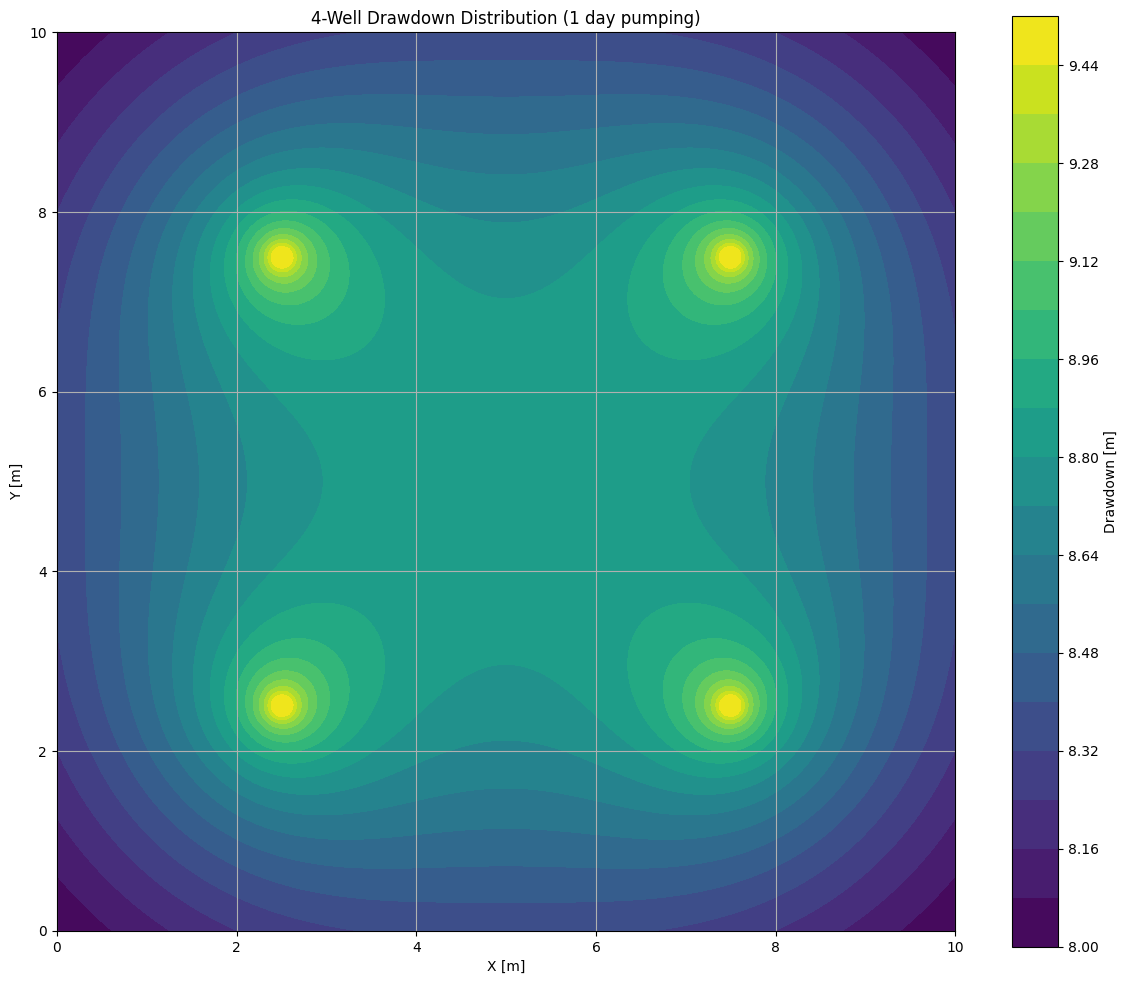

In [38]:
# Bonus Question
x = np.linspace(0, 10, 200)
y = np.linspace(0, 10, 200)
xi, yi = np.meshgrid(x, y)

pumps = [(2.5, 2.5), (2.5, 7.5), (7.5, 2.5), (7.5, 7.5)]

# Compute total drawdown
dd = np.zeros_like(xi)
for i in range(xi.shape[0]):
    for j in range(xi.shape[1]):
        r_total = 0
        for wx, wy in pumps:
            r = np.sqrt((xi[i,j] - wx)**2 + (yi[i,j] - wy)**2)
            r = np.maximum(r, 0.1)
            r_total += Theis_solution(t, r, Q_each, T, S)
        dd[i,j] = r_total

# Plotting
fig, ax = plt.subplots(figsize=(12, 10))
cs = ax.contourf(xi, yi, dd, levels=20, cmap='viridis')
ax.set_title('4-Well Drawdown Distribution (1 day pumping)')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_aspect('equal')
ax.grid(True)

fig.colorbar(cs, ax=ax, label='Drawdown [m]')
plt.tight_layout()
plt.show()

The contour plot above visualizes the drawdown distribution for the four-well Middle configuration after one day of pumping. Unlike the single well scenario, which produces a single steep cone of depression with extreme drawdown near the well center, the four-well configuration creates a much flatter and more uniform drawdown pattern across the construction site. As shown in the plot, the drawdown is evenly distributed with no extreme peaks, and the difference between the highest and lowest drawdown within the site is significantly reduced.

### Q9

In [39]:
r_building = 50.0
s_building = Theis_solution(t, r_building, Q_m3s, T, S)
print(f"Drawdown below building for single well: {s_building:.2f} m")
s_building_4wells = Theis_solution(t, r_building, 4*Q_each, T, S)
print(f"Drawdown below building with 4 wells: {s_building_4wells:.2f} m")

Drawdown below building for single well: 5.59 m
Drawdown below building with 4 wells: 5.58 m


The drawdown at the nearest bulidings located after 1 day of pumping would be 5.59 m for a single well and 5.58 m for the 4 well system. To minimise drawdown effects below the buildings a pumping well between the construction site and the buildings that reinjects the pumped water would be effective. Thus creating an artificial hydraulic boundry between drawdone on site and surrounding area.

## *Declaration of AI*

This notebook has been developed for assignment 3 in the course 12320 Hydrology F26 at DTU Lyngby.

This assingment has been produced with the use of ChatGPT model 5.3 during March and April of 2026.

The AI has been used to help with data infrastructure setup, syntax errors and generel coding assistance.

All contents of this notebook have been read, reviewed and edited to ensure it represents the understanding of the students of admission and fulfills assignment requirements. 

The students of admission takes full responsibility for the contents of this notebook.